In [20]:
import sys
sys.path.append("..")
import pandas as pd
from src.complaint.db import get_engine
from sqlalchemy import text

engine = get_engine()
pd.read_sql("SELECT count(*) FROM complaints_text", engine)

,count
0,3851396


### Examining how the product labels change over time

In [3]:
q = """
SELECT EXTRACT(YEAR FROM date_received)::int AS YEAR,
    product,
    count(*) AS n
FROM complaints_text
GROUP BY 1,2
ORDER BY 1,2
"""
df = pd.read_sql(q, engine)

In [5]:
df["year"].value_counts().sort_index()   # rows per year, 2015 to 2026

year
2015    12
2016    12
2017    18
2018     9
2019     9
2020     9
2021     9
2022     9
2023    14
2024    11
2025    11
2026    11
Name: count, dtype: int64

In [7]:
wide = df.pivot(index="product", columns="year", values="n")
wide.head()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
product,,,,,,,,,,,,
Bank account or service,4559.0,7755.0,2569.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking or savings account,NaN,NaN,4752.0,6999.0,7351.0,9530.0,12401.0,18032.0,28017.0,29485.0,51448.0,21335.0
Consumer Loan,2969.0,4666.0,1823.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit card,6243.0,9433.0,3161.0,NaN,NaN,NaN,NaN,NaN,12905.0,35451.0,41516.0,20435.0
Credit card or prepaid card,NaN,NaN,7799.0,11854.0,12526.0,17102.0,16607.0,21512.0,21283.0,NaN,NaN,NaN


In [8]:
life = (df.groupby("product")
          .agg(first=("year", "min"), last=("year", "max"), total=("n", "sum"))
          .sort_values("first"))
life

,first,last,total
product,,,
Bank account or service,2015,2017,14883
Consumer Loan,2015,2017,9458
Credit card,2015,2026,129144
Credit reporting,2015,2017,31587
Mortgage,2015,2026,147249
Other financial service,2015,2017,292
Money transfers,2015,2017,1497
Debt collection,2015,2026,445240
Payday loan,2015,2017,1745


**Observations**
- The CFPB changed its product taxonomy twice: in 2017 (e.g. `Credit card` + `Prepaid card` became `Credit card or prepaid card`, and `Bank account or service` became `Checking or savings account`) and in 2023 (`Credit reporting, credit repair...` became `Credit reporting or other personal consumer reports`, and `Debt or credit management` is new).
- Some labels split again later: `Credit card` reappears in 2023 after being folded into `Credit card or prepaid card`. So raw `product` doesn't mean the same thing across years, which is why we need the `product_group` mapping.
- A few legacy labels are tiny (`Virtual currency` = 16, `Other financial service` = 292) and only make sense merged into a broader group.

### Class Balance


<Axes: ylabel='product_group'>

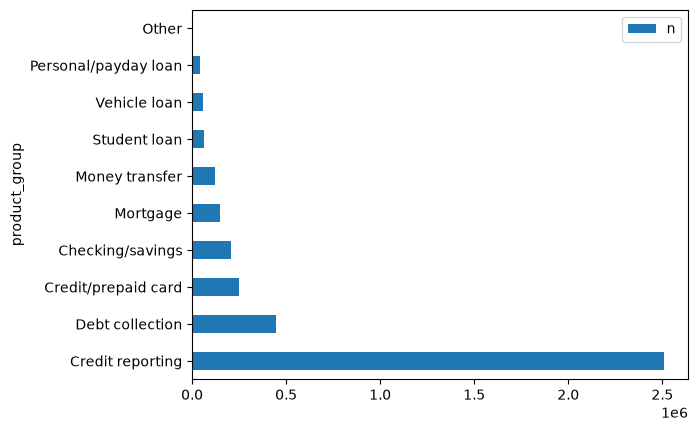

In [10]:
q = """
SELECT product_group, count(*) AS n
FROM complaints_text
GROUP BY 1 ORDER By 2 DESC
"""
cls = pd.read_sql(q, engine)
cls.plot.barh(x="product_group", y="n")

**Observations**
- The classes are very imbalanced. Credit reporting is ~65% of rows (2.51M), Debt collection is ~12%, and everything else is in single digits. `Other` is only 0.2% (~5.9k).
- If a model always predicted "Credit reporting" it would already get ~65% accuracy, so we should report macro-F1 and per-class metrics, not plain accuracy.
- We should consider downsampling Credit reporting and/or using class weights, and stratify the train/val/test splits.

### Text length

In [11]:
q = """
SELECT array_length(regexp_split_to_array(narrative, '\\s+'), 1) AS words
FROM narratives TABLESAMPLE SYSTEM (5)
"""
lens = pd.read_sql(q, engine)
lens["words"].describe(percentiles=[.5, .9, .95, .99])

count    193450.000000
mean        177.917710
std         221.660993
min           1.000000
50%         118.000000
90%         369.000000
95%         518.000000
99%        1017.000000
max        6291.000000
Name: words, dtype: float64

In [12]:
(lens["words"] < 20).mean()

np.float64(0.040139570948565524)

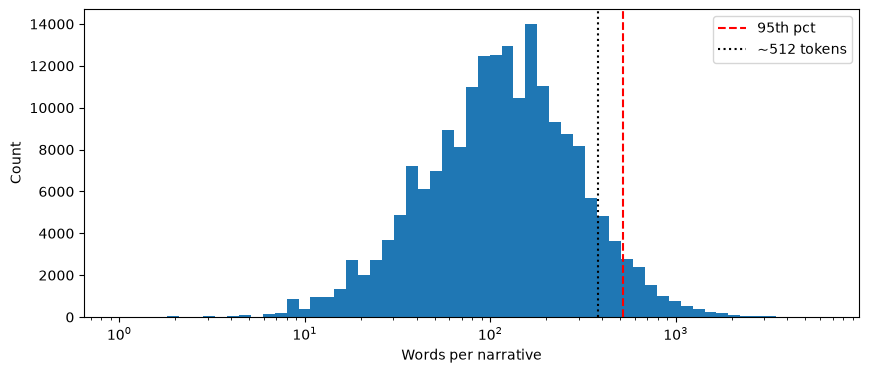

In [17]:
import matplotlib.pyplot as plt
import numpy as np

w = lens['words'].dropna()
bins = np.logspace(0, np.log10(w.max()), 60)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(w, bins=bins)
ax.set_xscale("log")
ax.axvline(w.quantile(0.95), color="red", linestyle="--", label="95th pct")
ax.axvline(380, color="black", linestyle=":", label="~512 tokens")
ax.set_xlabel("Words per narrative")
ax.set_ylabel("Count")
ax.legend()
plt.show()

**Observations**
- Narrative length is heavily right-skewed: median ~118 words, mean ~178, p95 ~518, p99 ~1,017, max ~6.3k.
- About 4% of narratives are under 20 words, which may be too little text to classify reliably.
- BERT-style models cap input at 512 tokens (about 380 words). That covers roughly 90% of narratives as they are, so we will have to truncate the rest. Long complaints usually state the issue early, so head truncation (or head+tail) should be fine. We could revisit this if long texts turn out to be misclassified.

### Redactions

In [23]:
q = """
SELECT
  avg((narrative LIKE '%XXXX%')::int) AS share_with_redaction,
  avg((length(narrative) - length(replace(narrative, 'XXXX', ''))) / 4.0) AS avg_per_text
FROM narratives TABLESAMPLE SYSTEM (5)
"""
pd.read_sql(text(q), engine)

,share_with_redaction,avg_per_text
0,0.67497,14.206407


**Observations**
- ~67% of narratives contain at least one `XXXX` redaction, with ~14 redaction tokens per text on average.
- These tokens carry no meaning but use up the token budget, and runs like `XX/XX/XXXX` split into several subword pieces. We should consider collapsing them into a single placeholder token before tokenizing.

### Duplications

In [24]:
q = """
SELECT count(*) AS total, count(DISTINCT md5(narrative)) AS distinct_texts
FROM narratives
"""
pd.read_sql(q, engine)

,total,distinct_texts
0,3851415,2596655


In [25]:
q = """
SELECT left(min(narrative), 150) AS preview, count(*) AS n
FROM narratives
GROUP BY md5(narrative)
HAVING count(*) > 1
ORDER BY n DESC LIMIT 10
"""
pd.read_sql(q, engine)

,preview,n
0,In accordance with the Fair Credit Reporting a...,27496
1,My credit reports are inaccurate. These inaccu...,24247
2,You have reported inaccurate and unauthorized ...,18444
3,"Upon reviewing my credit report, I have identi...",15803
4,I am writing to have the following information...,12204
5,The Fair Credit Reporting Act ( 15 U.S. Code 1...,10884
6,The Fair Credit Reporting Act ( 15 U.S. Code 1...,10120
7,I have not supplied proof under the doctrine o...,10087
8,Could you please take a moment to review and e...,7932
9,There are collection accounts on my report tha...,7832


**Observations**
- Only 2.60M of the 3.85M narratives are distinct, so ~33% are exact duplicates.
- The duplicates are mostly form letters: the top copies are FCRA dispute templates, each repeated 8k–27k times. They are concentrated in Credit reporting (~45% duplicated), then Money transfer (~20%) and Debt collection (~15%). The other groups are under 6%.
- This matters for evaluation: if copies of the same text end up in both train and test, scores will be inflated. We should dedupe by `md5(narrative)` before splitting, or split by hash group. Deduping also shrinks Credit reporting a lot, which partly fixes the class imbalance.

### Volume over time

In [26]:
q = """
SELECT date_trunc('month', date_received)::date AS month,
       product_group, count(*) AS n
FROM complaints_text
GROUP BY 1, 2
"""
vol = pd.read_sql(q, engine)

<Axes: xlabel='month'>

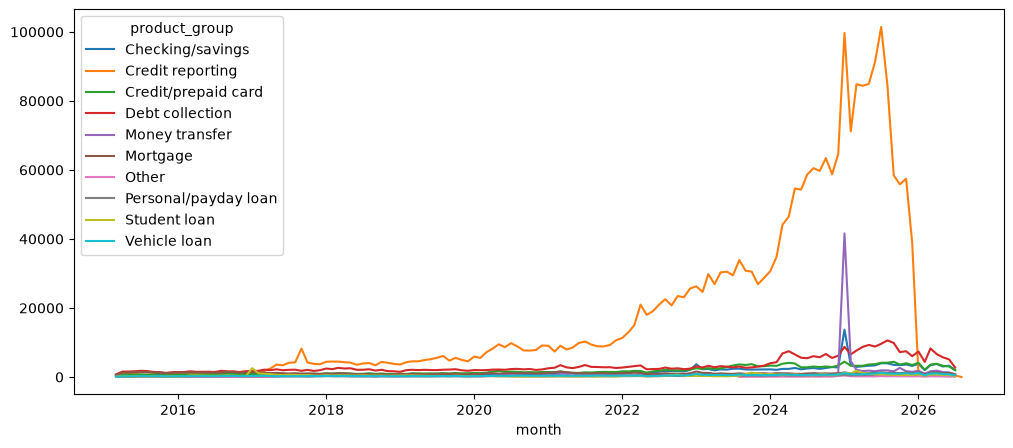

In [27]:
vol.pivot(index="month", columns="product_group", values="n").plot(figsize=(12, 5))

**Observations**
- Volume has grown steeply. Complaints with a narrative went from ~55k in 2015 to ~1.22M in 2025, and Credit reporting accounts for almost all of that growth.
- There is a one-month spike in Jan 2025 (~173k vs. ~105k in nearby months), and it is mostly outside Credit reporting.
- Credit reporting almost disappears in 2026: from 39–100k/month in 2025 to under 1k/month starting Jan 2026, while the other groups keep going. This looks like a change in how the data is collected or published, not a real drop in complaints. Data also ends abruptly at 2026-08-11, so the last month is incomplete.
- Because the class mix depends so much on time, a random split and a time-based split will give very different results. If we evaluate on a 2026 holdout, Credit reporting will be nearly missing from it.